# Session 1 — OLS by matrix algebra

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to lecture AE1.1 (Regression Review). This notebook derives the OLS
estimator in matrix form and then computes every piece by hand on a dataset
small enough to print: the estimator itself, the variance-covariance matrix,
standard errors, t-statistics, and confidence intervals. We verify each number
against `statsmodels`, use a Monte Carlo experiment to show what the
variance-covariance matrix actually describes, and close with the
Frisch–Waugh–Lovell theorem (regression anatomy) — what "holding other
regressors constant" means mechanically.

Requirements: `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`
(see the repo README for setup). Run the cells top to bottom; in the lecture we
step through them one at a time.


## 1. The model in matrix form

We work with the linear model

$$y = X\beta + \varepsilon,$$

where $y$ is $n \times 1$, $X$ is $n \times k$ (first column a constant),
$\beta$ is $k \times 1$, and $\varepsilon$ is $n \times 1$. The assumptions we
use today:

1. **Linearity**: the model above is the data-generating process.
2. **Zero conditional mean** (conditional exogeneity): $\mathbb{E}[\varepsilon \mid X] = 0$.
   (In panel data the term *strict* exogeneity means something stronger — all
   periods' regressors; that is Session 4's business.)
3. **No perfect collinearity**: $X$ has full column rank $k$, so $X'X$ is invertible.
4. **Spherical errors**: $\mathrm{Var}(\varepsilon \mid X) = \sigma^2 I_n$
   (homoskedasticity, no autocorrelation) — needed for the simple
   variance-covariance formula, not for the estimator itself.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(20260728)
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


## 2. A small dataset with known truth

Simulated data, deliberately: we choose the true $\beta$ ourselves, so we can
judge everything the estimator does against the truth. The example is a
textbook wage equation with $n = 12$ people,

$$\text{wage}_i = \beta_0 + \beta_1\,\text{schooling}_i + \beta_2\,\text{experience}_i + \varepsilon_i,$$

with hourly wage in euros, true values $\beta = (4,\ 1.2,\ 0.25)'$ and
$\varepsilon_i \sim N(0, \sigma^2)$, $\sigma = 1$. (Levels, not logs — logs are the
topic of session 2.) Nothing causal is claimed
here — this is the mechanics of the estimator. $n = 12$ is chosen so every
matrix fits on the screen.

In [2]:
n = 12
beta_true = np.array([4.0, 1.2, 0.25])
sigma_true = 1.0

schooling  = np.array([10, 11, 12, 12, 13, 14, 15, 16, 16, 17, 18, 18], dtype=float)
experience = np.array([28, 22, 25, 14, 18, 12, 15,  6, 10,  4,  2,  8], dtype=float)

eps = rng.normal(0.0, sigma_true, size=n)
wage = beta_true[0] + beta_true[1] * schooling + beta_true[2] * experience + eps

df = pd.DataFrame({"schooling": schooling, "experience": experience, "wage": wage})
df

,schooling,experience,wage
0,10.0,28.0,24.8585
1,11.0,22.0,22.7705
2,12.0,25.0,24.5078
3,12.0,14.0,22.9486
4,13.0,18.0,24.3708
5,14.0,12.0,24.2835
6,15.0,15.0,25.0496
7,16.0,6.0,25.4476
8,16.0,10.0,24.4760
9,17.0,4.0,25.1924


The design matrix $X$ stacks a column of ones (the constant) next to the
regressors. Keep the dimensions in your head at all times — most matrix-algebra
mistakes are dimension mistakes.

**Why a column of ones gives you the intercept.** The model
$y_i = \beta_0 + \beta_1 x_{1i} + \beta_2 x_{2i} + \varepsilon_i$ can be read as
$y_i = \beta_0 \cdot 1 + \beta_1 x_{1i} + \beta_2 x_{2i} + \varepsilon_i$: the
intercept is just the coefficient on a regressor that equals 1 for every
observation. Writing that regressor out as a column makes $X\beta$ produce
$\beta_0$ for everyone, so one formula, $\hat\beta = (X'X)^{-1}X'y$, estimates
the intercept and the slopes together. Nothing special happens to $\beta_0$;
it is treated exactly like the other coefficients.

Two consequences follow from the ones column alone. The first row of the
normal equations $X'e = 0$ reads $\mathbf{1}'e = \sum_i e_i = 0$: with a
constant in the model, the residuals average to zero *by construction*, and
the fitted line passes through the point of means $(\bar x_1, \bar x_2, \bar y)$.
Solving that row gives the familiar
$\hat\beta_0 = \bar y - \hat\beta_1 \bar x_1 - \hat\beta_2 \bar x_2$ — the
intercept is whatever it takes to make the line go through the means. Drop the
column and both properties disappear: the residuals no longer sum to zero and
the line is forced through the origin (exercise 3).

In [3]:
X = np.column_stack([np.ones(n), schooling, experience])   # n x k
y = wage                                                   # length-n 1-D array (numpy shape (n,)); treated as n x 1
k = X.shape[1]
names = ["const", "schooling", "experience"]

print("X is", X.shape, "| y is", y.shape)
print(X)

X is (12, 3) | y is (12,)
[[ 1. 10. 28.]
 [ 1. 11. 22.]
 [ 1. 12. 25.]
 [ 1. 12. 14.]
 [ 1. 13. 18.]
 [ 1. 14. 12.]
 [ 1. 15. 15.]
 [ 1. 16.  6.]
 [ 1. 16. 10.]
 [ 1. 17.  4.]
 [ 1. 18.  2.]
 [ 1. 18.  8.]]


## 3. Deriving the estimator

OLS chooses $\hat\beta$ to minimize the sum of squared residuals

$$S(\beta) = (y - X\beta)'(y - X\beta) = y'y - 2\beta'X'y + \beta'X'X\beta.$$

The first-order condition sets the gradient to zero:

$$\frac{\partial S}{\partial \beta} = -2X'y + 2X'X\beta \overset{!}{=} 0
\quad\Longrightarrow\quad X'X\,\hat\beta = X'y.$$

These are the **normal equations** — $k$ equations in $k$ unknowns. Under full
column rank $X'X$ is invertible and

$$\hat\beta = (X'X)^{-1}X'y.$$

Geometrically, $X\hat\beta$ is the orthogonal projection of $y$ onto the column
space of $X$: the residual vector is forced to be orthogonal to every regressor,
$X'e = 0$. We verify that numerically below.

In [4]:
XtX = X.T @ X          # k x k
Xty = X.T @ y          # k x 1

print("X'X =")
print(XtX)
print()
print("X'y =", Xty)

X'X =
[[  12.  172.  164.]
 [ 172. 2548. 2121.]
 [ 164. 2121. 3002.]]

X'y = [ 299.4992 4328.8097 4016.8646]


In [5]:
XtX_inv = np.linalg.inv(XtX)
beta_hat = XtX_inv @ Xty

comparison = pd.DataFrame({"true beta": beta_true, "beta_hat": beta_hat}, index=names)
comparison

,true beta,beta_hat
const,4.00,8.3826
schooling,1.20,0.9722
experience,0.25,0.1932


With $n = 12$ and $\sigma = 1$ the estimates sit near the truth but not on
it — that gap is sampling error, and quantifying it is exactly what the
variance-covariance matrix is for.

One practical note before we move on: `inv(X'X) @ X'y` is the formula you
derive, not the code you ship. Explicit inversion is numerically the worst way
to solve a linear system. Production code uses `np.linalg.solve`, a QR
factorization, or a pseudoinverse (`statsmodels` defaults to the Moore–Penrose
pseudoinverse). Same answer here, better behavior when $X'X$ is close to
singular.

In [6]:
beta_solve = np.linalg.solve(XtX, Xty)
assert np.allclose(beta_hat, beta_solve)

y_hat = X @ beta_hat
e = y - y_hat

print("X'e =", X.T @ e, " (zero up to floating point: residuals are orthogonal to X)")
print("SSR =", e @ e)

# the ones column at work: residuals sum to zero, and the intercept makes the line pass through the means
print("sum of residuals =", e.sum())
beta0_from_means = y.mean() - beta_hat[1] * schooling.mean() - beta_hat[2] * experience.mean()
print(f"beta_0 from the means = {beta0_from_means:.6f}   vs   beta_hat[0] = {beta_hat[0]:.6f}")

X'e = [-0. -0. -0.]  (zero up to floating point: residuals are orthogonal to X)
SSR = 7.088923846861651
sum of residuals = -9.343636975245317e-13
beta_0 from the means = 8.382588   vs   beta_hat[0] = 8.382588


## 4. The variance-covariance matrix of $\hat\beta$

Substitute the model into the estimator:

$$\hat\beta = (X'X)^{-1}X'(X\beta + \varepsilon) = \beta + (X'X)^{-1}X'\varepsilon.$$

Two things follow immediately. First, unbiasedness under zero conditional mean:
$\mathbb{E}[\hat\beta \mid X] = \beta$. Second, the sampling variance. Using
$\mathrm{Var}(Az) = A\,\mathrm{Var}(z)\,A'$ for fixed $A$,

$$\mathrm{Var}(\hat\beta \mid X)
= (X'X)^{-1}X'\,\underbrace{\mathrm{Var}(\varepsilon \mid X)}_{=\ \sigma^2 I_n}\,X(X'X)^{-1}
= \sigma^2 (X'X)^{-1}.$$

This $k \times k$ matrix is the object everything else hangs on:

- **Diagonal** entries are the variances of the individual coefficient
  estimates. Their square roots are the standard errors.
- **Off-diagonal** entries are covariances *between coefficient estimates
  across repeated samples*. They are not about correlation between regressors
  in your data — though correlated regressors are what produces them. You need
  them for any test involving more than one coefficient (Wald tests, linear
  combinations, delta method).

$\sigma^2$ is unknown, so we estimate it from the residuals:

$$s^2 = \frac{e'e}{n - k}.$$

The divisor is $n - k$, not $n$. The intuition: the residuals satisfy the $k$
orthogonality constraints $X'e = 0$, so only $n - k$ of them are free. The
result: with $e = M\varepsilon$, $M = I - X(X'X)^{-1}X'$ idempotent of rank
$n-k$, and spherical errors, $\mathbb{E}[e'e \mid X] = \sigma^2\,\mathrm{tr}(M) = (n-k)\sigma^2$.
Dividing by $n$ would bias $s^2$ downward — standard errors would be
systematically too small. (Under heteroskedasticity $s^2$ estimates an average
error variance and the formula above is the wrong target anyway — Session 4.)

In [7]:
s2 = (e @ e) / (n - k)
vcov = s2 * XtX_inv

print(f"s^2 = {s2:.6f}   (true sigma^2 = {sigma_true**2:.6f})")
print(f"s   = {np.sqrt(s2):.4f} (true sigma   = {sigma_true:.4f})")

pd.DataFrame(vcov, index=names, columns=names)

s^2 = 0.787658   (true sigma^2 = 1.000000)
s   = 0.8875 (true sigma   = 1.0000)


,const,schooling,experience
const,20.4036,-1.0913,-0.3436
schooling,-1.0913,0.0591,0.0178
experience,-0.3436,0.0178,0.0064


In [8]:
se = np.sqrt(np.diag(vcov))
pd.DataFrame({"beta_hat": beta_hat, "std. error": se}, index=names)

,beta_hat,std. error
const,8.3826,4.5170
schooling,0.9722,0.2431
experience,0.1932,0.0802


## 5. t-statistics, p-values, confidence intervals

Two routes lead to the same table. **Exact:** if additionally
$\varepsilon \mid X \sim N(0, \sigma^2 I_n)$, the studentized coefficient

$$t_j = \frac{\hat\beta_j - \beta_j^0}{\mathrm{se}(\hat\beta_j)}$$

follows a $t$ distribution with $n - k$ degrees of freedom under
$H_0: \beta_j = \beta_j^0$. The usual table tests $\beta_j^0 = 0$. The
$1-\alpha$ confidence interval is
$\hat\beta_j \pm t_{1-\alpha/2,\,n-k}\,\mathrm{se}(\hat\beta_j)$.

**Asymptotic:** without normality, $t_j$ is approximately standard normal in
large samples — but only with a standard error that is consistent for the
actual error structure (heteroskedasticity-robust or clustered where needed;
the classical $s^2(X'X)^{-1}$ is not). With $n = 12$ we are squarely in the
exact case and lean on normality; the $t_{n-k}$ critical values are the
finite-sample refinement that the asymptotic route does not offer.

In [9]:
dof = n - k
t_stat = beta_hat / se
p_val = 2 * stats.t.sf(np.abs(t_stat), df=dof)
t_crit = stats.t.ppf(0.975, df=dof)

results = pd.DataFrame({
    "coef": beta_hat,
    "se": se,
    "t": t_stat,
    "p": p_val,
    "ci_low": beta_hat - t_crit * se,
    "ci_high": beta_hat + t_crit * se,
}, index=names)
results

,coef,se,t,p,ci_low,ci_high
const,8.3826,4.5170,1.8558,0.0965,-1.8356,18.6008
schooling,0.9722,0.2431,3.9985,0.0031,0.4222,1.5222
experience,0.1932,0.0802,2.4108,0.0392,0.0119,0.3746


## 6. Verification against statsmodels

Every number above should match the canned routine to numerical tolerance
(`np.allclose`) — if it does not,
the derivation or the code is wrong. This check-against-a-reference habit is
worth keeping for the rest of your career.

In [10]:
import statsmodels.api as sm

fit = sm.OLS(y, X).fit()

assert np.allclose(fit.params, beta_hat)
assert np.allclose(fit.bse, se)
assert np.allclose(fit.tvalues, t_stat)
assert np.allclose(fit.pvalues, p_val)
assert np.allclose(fit.cov_params(), vcov)
print("all quantities match statsmodels exactly\n")

print(fit.summary(xname=names))

all quantities match statsmodels exactly

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     12.85
Date:                Mon, 12 Oct 2026   Prob (F-statistic):            0.00230
Time:                        12:40:45   Log-Likelihood:                -13.869
No. Observations:                  12   AIC:                             33.74
Df Residuals:                       9   BIC:                             35.19
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const     

## 7. What the variance-covariance matrix *is*: a Monte Carlo look

$\mathrm{Var}(\hat\beta \mid X)$ answers a repeated-sampling question: holding
$X$ fixed, if nature redrew the errors again and again, how would $\hat\beta$
scatter around $\beta$? We can run that thought experiment literally. Redraw
$\varepsilon$ 10,000 times, re-estimate each time, and compare the empirical
covariance matrix of the 10,000 estimates with the theoretical
$\sigma^2(X'X)^{-1}$.

In [11]:
R = 10_000
E = rng.normal(0.0, sigma_true, size=(n, R))          # each column: one redraw of eps
Y = (X @ beta_true)[:, None] + E                      # each column: one sample of y
B = np.linalg.solve(XtX, X.T @ Y)                     # k x R: one beta_hat per column

vcov_theory = sigma_true**2 * XtX_inv                 # true sigma^2 -- known in a simulation
vcov_mc = np.cov(B)

print("theoretical  sigma^2 (X'X)^-1:")
print(vcov_theory)
print()
print("empirical covariance of 10,000 beta_hat draws:")
print(vcov_mc)
print()
print("mean of beta_hat draws:", B.mean(axis=1), " vs true", beta_true, " (unbiasedness)")

theoretical  sigma^2 (X'X)^-1:
[[25.9041 -1.3855 -0.4363]
 [-1.3855  0.0751  0.0227]
 [-0.4363  0.0227  0.0082]]

empirical covariance of 10,000 beta_hat draws:
[[25.6131 -1.3679 -0.4332]
 [-1.3679  0.074   0.0225]
 [-0.4332  0.0225  0.0081]]

mean of beta_hat draws: [3.9364 1.2038 0.2511]  vs true [4.   1.2  0.25]  (unbiasedness)


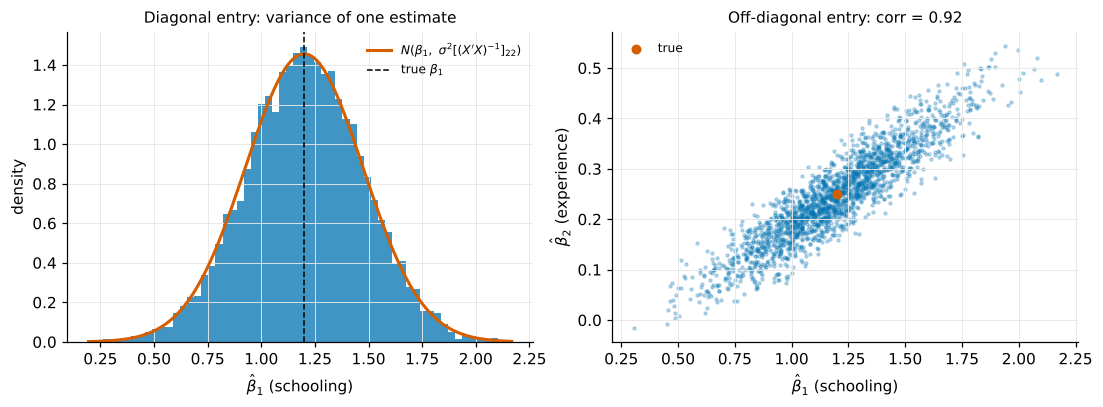

In [12]:
import matplotlib.pyplot as plt

# Okabe-Ito palette, minimal theme
BLUE, ORANGE, VERMILLION = "#0072B2", "#E69F00", "#D55E00"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "font.family": "sans-serif",
})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

# left: sampling distribution of the schooling coefficient
j = 1
ax = axes[0]
ax.hist(B[j], bins=60, density=True, color=BLUE, alpha=0.75)
grid = np.linspace(B[j].min(), B[j].max(), 300)
ax.plot(grid, stats.norm.pdf(grid, beta_true[j], np.sqrt(vcov_theory[j, j])),
        color=VERMILLION, lw=2, label=r"$N(\beta_1,\ \sigma^2[(X'X)^{-1}]_{22})$")
ax.axvline(beta_true[j], color="black", lw=1, ls="--", label=r"true $\beta_1$")
ax.set_xlabel(r"$\hat\beta_1$ (schooling)")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Diagonal entry: variance of one estimate", fontsize=10)

# right: joint scatter -- the off-diagonal entry is the tilt of this cloud
ax = axes[1]
ax.scatter(B[1, :2000], B[2, :2000], s=4, alpha=0.25, color=BLUE)
ax.scatter(*beta_true[1:], color=VERMILLION, zorder=3, label="true", s=30)
corr = vcov_theory[1, 2] / np.sqrt(vcov_theory[1, 1] * vcov_theory[2, 2])
ax.set_xlabel(r"$\hat\beta_1$ (schooling)")
ax.set_ylabel(r"$\hat\beta_2$ (experience)")
ax.legend(frameon=False, fontsize=8)
ax.set_title(f"Off-diagonal entry: corr = {corr:.2f}", fontsize=10)

plt.tight_layout()
plt.show()

Read the two panels against the matrix. The histogram is the sampling
distribution of one coefficient — its spread is a diagonal entry, and the
standard error from Section 4 estimates exactly this spread from a single
sample. The scatter shows two coefficients *jointly*: the cloud tilts upward because
$\mathrm{Cov}(\hat\beta_1, \hat\beta_2) > 0$ — a sample that overstates the
schooling coefficient tends to overstate the experience coefficient too. Note
the sign flip: schooling and experience are *negatively* correlated in $X$,
and with two regressors that produces a *positive* off-diagonal entry of
$(X'X)^{-1}$. Correlation between regressors and correlation between their
estimated coefficients are different objects, and here they have opposite
signs.

## 8. Where standard errors come from, mechanically

A useful way to compress the session: $[(X'X)^{-1}]_{jj}$ is large when the
regressor $x_j$ has little variation left after the other regressors have
explained what they can. Standard errors therefore explode under near-perfect
collinearity — the demonstration below adds a regressor that is schooling plus
tiny noise.

In [13]:
rng_local = np.random.default_rng(1)                     # own seed: re-running this cell gives the same output
x_noisy = schooling + rng_local.normal(0.0, 0.05, size=n)  # almost a copy of schooling
X_bad = np.column_stack([X, x_noisy])

fit_bad = sm.OLS(y, X_bad).fit()
compare = pd.DataFrame({
    "se, original model": np.append(se, np.nan),
    "se, with near-copy": fit_bad.bse,
}, index=names + ["schooling_copy"])
print("condition number of X'X:  original {:.0f}  vs  near-collinear {:,.0f}".format(
    np.linalg.cond(XtX), np.linalg.cond(X_bad.T @ X_bad)))
compare

condition number of X'X:  original 127837  vs  near-collinear 1,645,936


,"se, original model","se, with near-copy"
const,4.5170,5.0556
schooling,0.2431,10.0023
experience,0.0802,0.0905
schooling_copy,NaN,9.9078


The data still identify the *sum* of the two schooling coefficients well, but
not either one separately — and the variance-covariance matrix says so, through
huge diagonal entries and a correlation near $-1$ between the two estimates.


## 9. Regression anatomy: the Frisch–Waugh–Lovell theorem

What does the coefficient on schooling mean when experience is also in the
regression? The FWL theorem (Frisch and Waugh 1933; Lovell 1963; "regression
anatomy" in Angrist and Pischke 2009) says: it is the *bivariate* slope of $y$
on the part of schooling that the other regressors cannot explain. Three steps:

1. **Auxiliary regression.** Regress $x_1$ (schooling) on all other columns of
   $X$ (constant and experience); keep the residual $\tilde x_1$.
2. **Residualize.** $\tilde x_1 = x_1 - \hat x_1$ is the variation in
   schooling that is orthogonal to experience ("experience partialled out").
3. **Bivariate regression.** Regress $y$ on $\tilde x_1$ without an
   intercept (one is not needed: $\tilde x_1$ has mean zero because the
   constant was partialled out). The slope is

$$\hat\beta_1 = \frac{\widehat{\mathrm{Cov}}(y, \tilde x_1)}{\widehat{\mathrm{Var}}(\tilde x_1)},$$

numerically identical to the multivariate OLS coefficient. In matrix terms,
with $M_2 = I - X_2(X_2'X_2)^{-1}X_2'$ the residual-maker of the other
regressors, $\tilde x_1 = M_2 x_1$ and $\hat\beta_1 = (\tilde x_1'\tilde x_1)^{-1}\tilde x_1' y$.
The full FWL statement residualizes $y$ as well — regressing $M_2 y$ on
$M_2 x_1$ gives the same coefficient *and* the same residuals as the
multivariate regression; regressing raw $y$ on $M_2 x_1$ is the coefficient
shortcut (same slope, since $M_2$ is symmetric and idempotent, but not the
same residuals).


In [14]:
# Step 1-2: residualize schooling on the other regressors (constant, experience)
X2 = np.column_stack([np.ones(n), experience])            # everything except schooling
M2 = np.eye(n) - X2 @ np.linalg.solve(X2.T @ X2, X2.T)     # residual-maker matrix
x1_tilde = M2 @ schooling                                 # schooling with experience partialled out

# Step 3: bivariate slope of y on the residualized regressor
beta1_fwl = (x1_tilde @ y) / (x1_tilde @ x1_tilde)

print(f"multivariate OLS  beta_1 = {beta_hat[1]:.6f}")
print(f"FWL (3 steps)     beta_1 = {beta1_fwl:.6f}")
assert np.isclose(beta_hat[1], beta1_fwl)

# the same slope from covariance / variance, and the same residuals
print("Cov(y, x1~)/Var(x1~) =", np.cov(y, x1_tilde, ddof=1)[0, 1] / np.var(x1_tilde, ddof=1))
e_fwl = M2 @ y - beta1_fwl * x1_tilde                      # residualize y as well -> identical residuals
print("max |e_multivariate - e_FWL| =", np.abs(e - e_fwl).max())


multivariate OLS  beta_1 = 0.972193
FWL (3 steps)     beta_1 = 0.972193
Cov(y, x1~)/Var(x1~) = 0.9721931076114378
max |e_multivariate - e_FWL| = 1.2723155862204294e-13


Two practical consequences:

- **Interpretation.** $\hat\beta_1$ uses only the variation in schooling that
  is *not* predictable from experience. If schooling and experience were
  perfectly collinear, $\tilde x_1$ would be zero and $\hat\beta_1$ undefined —
  the collinearity demonstration above, seen from the other side.
- **Visualization.** A multivariate coefficient can always be drawn as a 2-D
  scatter: $y$ (or residualized $y$) against $\tilde x_1$. The added-variable
  plot below is exactly that; its slope is $\hat\beta_1$.

The coefficient is exact; the standard error that an off-the-shelf bivariate
fit reports is not. It uses the wrong residual degrees of freedom ($n-1$ or
$n-2$ instead of $n-k$), which at $n = 12$ is not a small difference. Use the
full model's $s^2$ and $n-k$ — or simply the multivariate fit — for inference.


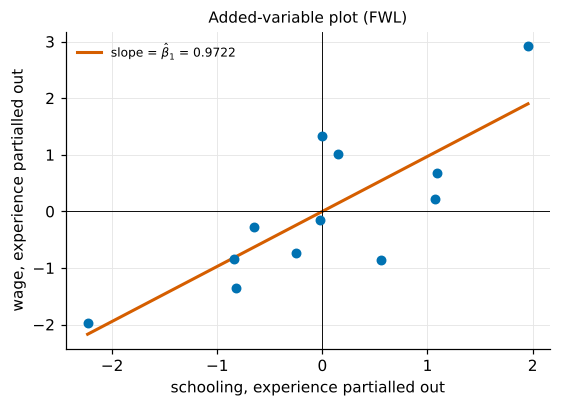

statsmodels slope on residualized data: 0.972193107611435


In [15]:
y_tilde = M2 @ y                                           # y with experience partialled out

fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.scatter(x1_tilde, y_tilde, color=BLUE, s=30, zorder=3)
grid = np.linspace(x1_tilde.min(), x1_tilde.max(), 50)
ax.plot(grid, beta1_fwl * grid, color=VERMILLION, lw=2,
        label=fr"slope = $\hat\beta_1$ = {beta1_fwl:.4f}")
ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("schooling, experience partialled out")
ax.set_ylabel("wage, experience partialled out")
ax.set_title("Added-variable plot (FWL)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# cross-check: statsmodels' own partial regression slope
fit2 = sm.OLS(y_tilde, x1_tilde).fit()
print("statsmodels slope on residualized data:", fit2.params[0])


## 10. Exercises

1. **Degrees of freedom.** Recompute $s^2$ dividing by $n$ instead of $n - k$.
   In the Monte Carlo, compare the mean of both versions across draws with the
   true $\sigma^2 = 1$. Which one is biased, and in which direction?
2. **Sample size.** Fix a regressor DGP (e.g. schooling uniform on 10–18,
   experience uniform on 2–28, independent) and, for each
   $n \in \{12, 48, 192, 768\}$, draw 2,000 samples and record $\hat\beta_1$.
   Plot the standard deviation of $\hat\beta_1$ across draws against
   $n^{-1/2}$: the points should lie on a line through the origin. That is
   the $1/\sqrt{n}$ rate — one draw per $n$ cannot show it.
3. **No intercept.** Re-estimate the model dropping the constant from $X$.
   Compare $\hat\beta_1$ with the truth and explain the result using the
   projection interpretation from Section 3.
4. **A Wald test by hand.** Test $H_0: \beta_1 = 5\,\beta_2$ using
   $\hat\beta$ and the estimated variance-covariance matrix: write the
   restriction as $R\beta = 0$, compute
   $W = (R\hat\beta)'[R\,\hat V\,R']^{-1}(R\hat\beta)$, and compare with
   `fit.wald_test`. This is where the off-diagonal entries earn their keep.
5. **FWL the other way round.** Repeat Section 9 for the experience
   coefficient (partial out the constant and schooling). Then verify that
   partialling out only the constant from both $y$ and a regressor gives the
   familiar demeaned covariance formula for the bivariate slope.


## References and outlook

- Cunningham (2021), *Causal Inference: The Mixtape*, **1st edition**, ch. 2
  (Probability and Regression Review) — the scalar derivation, the
  summation-operator view and regression anatomy. The chapter was dropped
  from the 2nd edition; the 1st edition stays online at
  [mixtape-1ed.netlify.app](https://mixtape-1ed.netlify.app/02-probability_and_regression).
- Cunningham (2026), *Causal Inference: The Mixtape*, 2nd edition (online),
  [Section 5.9 Regression](https://mixtape.scunning.com/05-causal_cross_sectional_designs#regression)
  — the Frisch–Waugh–Lovell theorem with a simulation, and the "canonical OLS
  model".
- Huntington-Klein (2025), *The Effect*, 2nd edition, ch. 13 (Regression) —
  regression as statistical adjustment, the applied companion to today's
  mechanics. Free at
  [theeffectbook.net](https://theeffectbook.net/ch-StatisticalAdjustment.html).
- Hayashi (2000), *Econometrics*, ch. 1 — the finite-sample theory of OLS in
  exactly today's notation, with proofs.

Sessions 2 and 3 cover the applied part of the regression review:
interpreting coefficients on logged variables (and what goes wrong with
zeros), and interaction effects.
